In [1]:
print("hello")

hello


1. Imports and settings
Uses the filtered CSV and also applies the seven exclusions defensively. Results go into a separate folder

In [ ]:
from pathlib import Path
import gc
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from threadpoolctl import threadpool_limits

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    ExtraTreesRegressor,
)
from sklearn.model_selection import (
    GridSearchCV,
    ParameterGrid,
    GroupShuffleSplit,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from IPython.display import display


BASE_FOLDER = Path(
    r"C:\Users\pkmpp\Documents\GitHub\J26-DS-323\experiments\pasan\step by step\data"
)

DATA_FILE = (
    BASE_FOLDER
    / "solar_15min_with_time_features_03 combine_wether_data_filtered.csv"
)

RESULT_FOLDER = BASE_FOLDER / "gridsearch_random_days_07 train 15 min"
RESULT_FOLDER.mkdir(parents=True, exist_ok=True)

SEED = 42

MODEL_THREADS = 2
GRID_SEARCH_JOBS = 1

N_FOLDS = 3

# Fractions of unique dates, not individual rows.
TEST_FRACTION = 0.20
CV_VALIDATION_FRACTION = 0.20

TARGET_COLUMN = "power_w_per_kwp"

EXCLUDED_DEVICES = {
    11: "1801150245270078",
    20: "18050B0239120029",
    23: "10050A021914000",
    30: "1805090245220419",
    36: "1031721264210116",
    43: "1801151255110048",
    46: "3801150252110059",
}

FEATURE_COLUMNS = [
    "weather_temperature_c",
    "weather_relative_humidity_pct",
    "weather_wind_speed_ms",
    "weather_cloud_cover_pct",
    "weather_cloud_cover_low_pct",
    "weather_cloud_cover_mid_pct",
    "weather_cloud_cover_high_pct",
    "weather_ghi_instant_wm2",
    "weather_dni_instant_wm2",
    "weather_dhi_instant_wm2",
    "weather_preceding_hour_precipitation_mm",
    "weather_preceding_hour_rain_mm",
    "sun_elevation_deg",
    "sun_azimuth_sin",
    "sun_azimuth_cos",
    "latitude",
    "longitude",
    "pv_capacity_kwp",
    "time_of_day_sin",
    "time_of_day_cos",
    "day_of_year_sin",
    "day_of_year_cos",
]


def postprocess_predictions(predictions):
    """Apply the same nonnegative rule to every model."""
    predictions = np.asarray(predictions, dtype=float).reshape(-1)

    if not np.isfinite(predictions).all():
        raise ValueError("Model produced nonfinite predictions")

    return np.maximum(predictions, 0)


def json_default(value):
    """Handle NumPy values when saving metadata."""
    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, (Path, pd.Timestamp)):
        return str(value)

    raise TypeError(
        f"Cannot serialize {type(value).__name__}"
    )

2. Load and validate the dataset
The target already represents power per installed capacity in W/kWp. Features use float64 to improve Ridge’s numerical stability.

In [3]:
required_columns = list(dict.fromkeys([
    "inverterSn",
    "timestamp_5min",
    TARGET_COLUMN,
    *FEATURE_COLUMNS,
]))

df = pd.read_csv(
    DATA_FILE,
    usecols=required_columns,
    dtype={"inverterSn": "string"},
    encoding="utf-8-sig",
)

df["inverterSn"] = df["inverterSn"].str.strip()

if (
    df["inverterSn"].isna().any()
    or df["inverterSn"].eq("").any()
):
    raise ValueError("Missing inverter identifiers")

excluded_mask = df["inverterSn"].isin(
    EXCLUDED_DEVICES.values()
)

print(
    "Excluded-device rows removed:",
    f"{int(excluded_mask.sum()):,}",
)

df = df.loc[~excluded_mask].copy()

df["_time"] = pd.to_datetime(
    df["timestamp_5min"],
    utc=True,
    format="mixed",
    errors="raise",
).dt.tz_convert("Asia/Colombo")

if df["_time"].isna().any():
    raise ValueError("Missing timestamps")

if df.duplicated(["inverterSn", "_time"]).any():
    raise ValueError("Duplicate inverter/timestamp pairs")

if not df["_time"].eq(
    df["_time"].dt.floor("15min")
).all():
    raise ValueError("Some rows are not on the 15-minute grid")

for column in [TARGET_COLUMN, *FEATURE_COLUMNS]:
    df[column] = pd.to_numeric(
        df[column],
        errors="raise",
    )

df[FEATURE_COLUMNS] = df[FEATURE_COLUMNS].replace(
    [np.inf, -np.inf],
    np.nan,
)

valid_target = (
    np.isfinite(df[TARGET_COLUMN])
    & df[TARGET_COLUMN].ge(0)
)

print(
    "Invalid-target rows excluded:",
    int((~valid_target).sum()),
)

df = df.loc[valid_target].copy()

if (
    ~np.isfinite(df["pv_capacity_kwp"])
    | df["pv_capacity_kwp"].le(0)
).any():
    raise ValueError("Missing or invalid installed capacity")

# Keep intervals starting 06:00 through 18:45.
minutes = (
    df["_time"].dt.hour * 60
    + df["_time"].dt.minute
)

inside_window = (
    minutes.ge(6 * 60)
    & minutes.lt(19 * 60)
)

print(
    "Rows outside interval window excluded:",
    int((~inside_window).sum()),
)

df = df.loc[inside_window].copy()

df = df.sort_values(
    ["_time", "inverterSn"]
).reset_index(drop=True)

if df.empty:
    raise ValueError("No usable rows")

df["_date"] = df["_time"].dt.normalize()

X = df[FEATURE_COLUMNS].astype("float64")
y = df[TARGET_COLUMN].astype("float64")

meta = df[[
    "inverterSn",
    "_time",
    "_date",
    "pv_capacity_kwp",
]].copy()

assert not meta["inverterSn"].isin(
    EXCLUDED_DEVICES.values()
).any()

print("Rows:", f"{len(df):,}")
print("Inverters:", meta["inverterSn"].nunique())
print("Calendar days:", meta["_date"].nunique())
print(
    "Date range:",
    meta["_time"].min(),
    "to",
    meta["_time"].max(),
)

display(
    X.isna()
    .sum()
    .rename("missing_feature_values")
    .to_frame()
)

Excluded-device rows removed: 0
Invalid-target rows excluded: 0
Rows outside interval window excluded: 740
Rows: 767,039
Inverters: 42
Calendar days: 1029
Date range: 2023-09-19 11:45:00+05:30 to 2026-08-01 18:45:00+05:30


,missing_feature_values
weather_temperature_c,0
weather_relative_humidity_pct,0
weather_wind_speed_ms,0
weather_cloud_cover_pct,0
weather_cloud_cover_low_pct,0
weather_cloud_cover_mid_pct,0
weather_cloud_cover_high_pct,0
weather_ghi_instant_wm2,0
weather_dni_instant_wm2,0
weather_dhi_instant_wm2,0


3. Create development data, test data, and the baseline
The test set contains randomly selected whole local dates across all devices.
The baseline uses the previous calendar day’s same inverter and time slot. It assumes yesterday’s actual measurements are available at midnight before each target day. Those observations may belong to either split; they are used only for baseline evaluation, never as model inputs.

In [4]:
target_lookup = pd.Series(
    y.to_numpy(),
    index=pd.MultiIndex.from_arrays([
        meta["inverterSn"],
        meta["_time"],
    ]),
)

previous_day_keys = pd.MultiIndex.from_arrays([
    meta["inverterSn"],
    meta["_time"] - pd.Timedelta(days=1),
])

baseline_all = target_lookup.reindex(
    previous_day_keys
).to_numpy(dtype=float)

day_groups = meta["_date"].dt.strftime("%Y-%m-%d")

outer_split = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_FRACTION,
    random_state=SEED,
)

development_idx, test_idx = next(
    outer_split.split(
        X,
        y,
        groups=day_groups,
    )
)

X_dev = X.iloc[development_idx].reset_index(drop=True)
y_dev = y.iloc[development_idx].reset_index(drop=True)
meta_dev = meta.iloc[development_idx].reset_index(drop=True)

X_test = X.iloc[test_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)
meta_test = meta.iloc[test_idx].reset_index(drop=True)

baseline_dev = baseline_all[development_idx]
baseline_test = baseline_all[test_idx]

development_dates = set(meta_dev["_date"])
test_dates = set(meta_test["_date"])

assert development_dates.isdisjoint(test_dates)

print("Development rows:", f"{len(X_dev):,}")
print("Test rows:", f"{len(X_test):,}")
print("Development days:", len(development_dates))
print("Test days:", len(test_dates))
print(
    "Actual test-row percentage:",
    f"{100 * len(X_test) / len(X):.2f}%",
)

# Save exact split assignments.
split_assignments = meta.copy()
split_assignments["split"] = "development"

split_assignments.loc[
    test_idx, "split"
] = "test"

split_assignments.to_csv(
    RESULT_FOLDER / "train_test_assignments.csv",
    index=False,
)

display(
    split_assignments.groupby("split").agg(
        rows=("inverterSn", "size"),
        inverters=("inverterSn", "nunique"),
        days=("_date", "nunique"),
        earliest_date=("_date", "min"),
        latest_date=("_date", "max"),
    )
)

Development rows: 617,423
Test rows: 149,616
Development days: 823
Test days: 206
Actual test-row percentage: 19.51%


,rows,inverters,days,earliest_date,latest_date
split,,,,,
development,617423,42,823,2023-09-19 00:00:00+05:30,2026-08-01 00:00:00+05:30
test,149616,42,206,2023-10-10 00:00:00+05:30,2026-07-30 00:00:00+05:30


4. Create random whole-day cross-validation folds
Each fold randomly holds out 20% of development dates for validation. No date appears in both training and validation within a fold, and final-test dates are excluded from every fold.
These are repeated random splits, so validation dates can recur across different folds.

In [5]:
development_groups = (
    meta_dev["_date"].dt.strftime("%Y-%m-%d")
)

inner_split = GroupShuffleSplit(
    n_splits=N_FOLDS,
    test_size=CV_VALIDATION_FRACTION,
    random_state=SEED + 1,
)

cv_folds = []
fold_records = []
fold_day_records = []

for fold_number, (train_idx, validation_idx) in enumerate(
    inner_split.split(
        X_dev,
        y_dev,
        groups=development_groups,
    ),
    start=1,
):
    train_dates = set(
        meta_dev.iloc[train_idx]["_date"]
    )

    validation_dates = set(
        meta_dev.iloc[validation_idx]["_date"]
    )

    assert train_dates.isdisjoint(validation_dates)
    assert train_dates.isdisjoint(test_dates)
    assert validation_dates.isdisjoint(test_dates)

    if not np.isfinite(
        baseline_dev[validation_idx]
    ).any():
        raise ValueError(
            f"No previous-day baseline available "
            f"in fold {fold_number}"
        )

    cv_folds.append((train_idx, validation_idx))

    fold_records.append({
        "fold": fold_number,
        "train_rows": len(train_idx),
        "validation_rows": len(validation_idx),
        "train_days": len(train_dates),
        "validation_days": len(validation_dates),
    })

    for role, dates in [
        ("train", train_dates),
        ("validation", validation_dates),
    ]:
        for date in sorted(dates):
            fold_day_records.append({
                "fold": fold_number,
                "date": date,
                "role": role,
            })

fold_table = pd.DataFrame(fold_records)

fold_table.to_csv(
    RESULT_FOLDER / "random_day_folds.csv",
    index=False,
)

pd.DataFrame(fold_day_records).to_csv(
    RESULT_FOLDER / "cv_day_assignments.csv",
    index=False,
)

display(fold_table)

,fold,train_rows,validation_rows,train_days,validation_days
0,1,495773,121650,658,165
1,2,493297,124126,658,165
2,3,493971,123452,658,165


5. Define evaluation functions
Grid search uses negative MAE because scikit-learn selects larger scores. Reports convert it back to positive MAE.
The scorer also evaluates rows where the baseline is available. Macro device MAE gives each evaluated inverter equal weight.

In [6]:
def calculate_metrics(actual, predicted, inverter_ids):
    actual = np.asarray(
        actual, dtype=float
    ).reshape(-1)

    predicted = np.asarray(
        predicted, dtype=float
    ).reshape(-1)

    inverter_ids = np.asarray(
        inverter_ids
    ).reshape(-1)

    if not (
        len(actual)
        == len(predicted)
        == len(inverter_ids)
    ):
        raise ValueError("Evaluation array lengths do not match")

    if len(actual) == 0:
        raise ValueError("No rows available for evaluation")

    if not (
        np.isfinite(actual).all()
        and np.isfinite(predicted).all()
    ):
        raise ValueError("Nonfinite evaluation values")

    errors = pd.DataFrame({
        "inverterSn": inverter_ids,
        "absolute_error": np.abs(actual - predicted),
    })

    return {
        "rows": len(actual),
        "MAE_W_per_kWp": float(
            mean_absolute_error(actual, predicted)
        ),
        "RMSE_W_per_kWp": float(
            np.sqrt(mean_squared_error(actual, predicted))
        ),
        "R2": (
            float(r2_score(actual, predicted))
            if len(actual) > 1 and np.var(actual) > 0
            else np.nan
        ),
        "macro_device_MAE": float(
            errors.groupby("inverterSn")["absolute_error"]
            .mean()
            .mean()
        ),
    }


def grid_scorer(estimator, X_validation, y_validation):
    predictions = postprocess_predictions(
        estimator.predict(X_validation)
    )

    # Original development indexes survive sklearn's row selection.
    row_indices = X_validation.index.to_numpy()

    inverter_ids = meta_dev.loc[
        row_indices, "inverterSn"
    ].to_numpy()

    actual = np.asarray(y_validation, dtype=float)

    metrics = calculate_metrics(
        actual,
        predictions,
        inverter_ids,
    )

    available = np.isfinite(
        baseline_dev[row_indices]
    )

    if not available.any():
        raise ValueError(
            "No baseline-covered rows in validation fold"
        )

    shared_metrics = calculate_metrics(
        actual[available],
        predictions[available],
        inverter_ids[available],
    )

    return {
        "neg_mae": -metrics["MAE_W_per_kWp"],
        "neg_rmse": -metrics["RMSE_W_per_kWp"],
        "r2": metrics["R2"],
        "neg_macro_mae": -metrics["macro_device_MAE"],
        "neg_shared_mae": -shared_metrics["MAE_W_per_kWp"],
        "neg_shared_rmse": -shared_metrics["RMSE_W_per_kWp"],
    }

6. Define pipelines and parameter grids
Only Ridge receives feature standardization. Every model receives median imputation fitted separately on each training fold.
Ridge uses the SVD solver to avoid the earlier ill-conditioned solver warning.

In [7]:
def make_pipeline(estimator, scale=False):
    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True,
            ),
        ),
    ]

    if scale:
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", estimator))

    return Pipeline(steps)


MODEL_SPECS = {
    "Ridge": {
        "pipeline": make_pipeline(
            Ridge(solver="svd"),
            scale=True,
        ),
        "grid": {
            "model__alpha": [0.1, 1.0, 10.0, 100.0],
        },
    },

    "HistGradientBoosting": {
        "pipeline": make_pipeline(
            HistGradientBoostingRegressor(
                learning_rate=0.05,
                max_iter=300,
                min_samples_leaf=30,
                early_stopping=False,
                random_state=SEED,
            )
        ),
        "grid": {
            "model__max_leaf_nodes": [15, 31],
            "model__l2_regularization": [0.0, 1.0],
        },
    },

    "RandomForest": {
        "pipeline": make_pipeline(
            RandomForestRegressor(
                n_estimators=150,
                max_features=0.8,
                n_jobs=MODEL_THREADS,
                random_state=SEED,
            )
        ),
        "grid": {
            "model__max_depth": [12, 18],
            "model__min_samples_leaf": [10, 30],
        },
    },

    "ExtraTrees": {
        "pipeline": make_pipeline(
            ExtraTreesRegressor(
                n_estimators=150,
                max_features=0.8,
                n_jobs=MODEL_THREADS,
                random_state=SEED,
            )
        ),
        "grid": {
            "model__max_depth": [12, 18],
            "model__min_samples_leaf": [10, 30],
        },
    },

    "LightGBM": {
        "pipeline": make_pipeline(
            LGBMRegressor(
                objective="regression",
                n_estimators=400,
                learning_rate=0.05,
                reg_lambda=1.0,
                n_jobs=MODEL_THREADS,
                random_state=SEED,
                verbosity=-1,
            )
        ),
        "grid": {
            "model__num_leaves": [15, 31],
            "model__min_child_samples": [20, 50],
        },
    },

    "XGBoost": {
        "pipeline": make_pipeline(
            XGBRegressor(
                objective="reg:squarederror",
                tree_method="hist",
                n_estimators=400,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=1.0,
                n_jobs=MODEL_THREADS,
                random_state=SEED,
            )
        ),
        "grid": {
            "model__max_depth": [4, 6],
            "model__min_child_weight": [5, 20],
        },
    },

    "CatBoost": {
        "pipeline": make_pipeline(
            CatBoostRegressor(
                loss_function="RMSE",
                iterations=400,
                learning_rate=0.05,
                thread_count=MODEL_THREADS,
                random_seed=SEED,
                verbose=False,
                allow_writing_files=False,
            )
        ),
        "grid": {
            "model__depth": [4, 6],
            "model__l2_leaf_reg": [3.0, 10.0],
        },
    },
}


# Edit this list to run selected models.
MODELS_TO_RUN = list(MODEL_SPECS)

# Example:
# MODELS_TO_RUN = ["Ridge", "LightGBM", "XGBoost"]

if not MODELS_TO_RUN:
    raise ValueError("Select at least one model")

unknown_models = set(MODELS_TO_RUN) - set(MODEL_SPECS)

if unknown_models:
    raise ValueError(f"Unknown models: {unknown_models}")

total_candidates = sum(
    len(ParameterGrid(MODEL_SPECS[name]["grid"]))
    for name in MODELS_TO_RUN
)

print("Models:", MODELS_TO_RUN)
print("Parameter combinations:", total_candidates)
print("Cross-validation fits:", total_candidates * N_FOLDS)

Models: ['Ridge', 'HistGradientBoosting', 'RandomForest', 'ExtraTrees', 'LightGBM', 'XGBoost', 'CatBoost']
Parameter combinations: 28
Cross-validation fits: 84


7. Evaluate the previous-day baseline
The baseline is evaluated on the same validation folds used by the learned models.

In [8]:
baseline_results = []

for fold_number, (_, validation_idx) in enumerate(
    cv_folds,
    start=1,
):
    baseline_predictions = baseline_dev[validation_idx]
    available = np.isfinite(baseline_predictions)

    metrics = calculate_metrics(
        y_dev.iloc[validation_idx].to_numpy()[available],
        baseline_predictions[available],
        meta_dev.iloc[validation_idx][
            "inverterSn"
        ].to_numpy()[available],
    )

    baseline_results.append({
        "model": "PreviousDayBaseline",
        "fold": fold_number,
        "coverage_percent": float(available.mean() * 100),
        **metrics,
    })

baseline_results = pd.DataFrame(baseline_results)

baseline_results.to_csv(
    RESULT_FOLDER / "baseline_cv_results.csv",
    index=False,
)

display(baseline_results)

,model,fold,coverage_percent,rows,MAE_W_per_kWp,RMSE_W_per_kWp,R2,macro_device_MAE
0,PreviousDayBaseline,1,94.523633,114988,100.485754,160.603263,0.568841,94.973417
1,PreviousDayBaseline,2,94.744050,117602,98.921080,159.215577,0.571541,96.304002
2,PreviousDayBaseline,3,94.676473,116880,99.662298,160.287371,0.544165,95.566409


8. Run GridSearchCV for all selected models
The search runs one fit at a time to limit memory use. Random Forest and Extra Trees can take substantial time.
Each model’s best parameters are selected using mean validation MAE.

In [9]:
search_summaries = []
best_parameters = {}

for model_name in MODELS_TO_RUN:
    spec = MODEL_SPECS[model_name]

    print(f"\n========== {model_name} ==========", flush=True)

    search = GridSearchCV(
        estimator=clone(spec["pipeline"]),
        param_grid=spec["grid"],
        scoring=grid_scorer,
        cv=cv_folds,
        refit=False,
        n_jobs=GRID_SEARCH_JOBS,
        pre_dispatch=1,
        return_train_score=False,
        error_score="raise",
        verbose=2,
    )

    started = time.perf_counter()

    with threadpool_limits(limits=MODEL_THREADS):
        search.fit(X_dev, y_dev)

    elapsed = time.perf_counter() - started

    results = pd.DataFrame(search.cv_results_)

    results.to_csv(
        RESULT_FOLDER / f"{model_name}_gridsearch_results.csv",
        index=False,
    )

    best_index = int(
        np.nanargmax(
            results["mean_test_neg_mae"].to_numpy()
        )
    )

    best_row = results.iloc[best_index]
    params = dict(best_row["params"])

    best_parameters[model_name] = params

    search_summaries.append({
        "model": model_name,
        "mean_CV_MAE": float(-best_row["mean_test_neg_mae"]),
        "std_CV_MAE": float(best_row["std_test_neg_mae"]),
        "mean_CV_RMSE": float(-best_row["mean_test_neg_rmse"]),
        "mean_CV_R2": float(best_row["mean_test_r2"]),
        "mean_macro_device_MAE": float(
            -best_row["mean_test_neg_macro_mae"]
        ),
        "shared_rows_CV_MAE": float(
            -best_row["mean_test_neg_shared_mae"]
        ),
        "shared_rows_CV_RMSE": float(
            -best_row["mean_test_neg_shared_rmse"]
        ),
        "mean_fit_seconds": float(best_row["mean_fit_time"]),
        "total_search_seconds": float(elapsed),
        "best_parameters": json.dumps(
            params,
            default=json_default,
        ),
    })

    pd.DataFrame(search_summaries).to_csv(
        RESULT_FOLDER / "gridsearch_model_comparison.csv",
        index=False,
    )

    with (RESULT_FOLDER / "best_parameters.json").open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            best_parameters,
            file,
            indent=2,
            default=json_default,
        )

    print("Best parameters:", params)
    print(
        "Mean CV MAE:",
        round(-best_row["mean_test_neg_mae"], 2),
    )
    print("Search seconds:", round(elapsed, 1))

    del search, results
    gc.collect()

print("\nGrid searches completed")


========== Ridge ==========
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ...................................model__alpha=0.1; total time=   1.9s
[CV] END ...................................model__alpha=0.1; total time=   1.8s
[CV] END ...................................model__alpha=0.1; total time=   1.8s
[CV] END ...................................model__alpha=1.0; total time=   1.7s
[CV] END ...................................model__alpha=1.0; total time=   1.6s
[CV] END ...................................model__alpha=1.0; total time=   1.7s
[CV] END ..................................model__alpha=10.0; total time=   1.8s
[CV] END ..................................model__alpha=10.0; total time=   1.9s
[CV] END ..................................model__alpha=10.0; total time=   1.8s
[CV] END .................................model__alpha=100.0; total time=   1.8s
[CV] END .................................model__alpha=100.0; total time=   1.9s
[CV] END ...........

9. Compare tuned models
These are tuning scores, which can be optimistic because they also selected the hyperparameters. Final-test dates have not been used for fitting or model selection in this run.

,model,mean_CV_MAE,std_CV_MAE,mean_CV_RMSE,mean_CV_R2,mean_macro_device_MAE,shared_rows_CV_MAE,shared_rows_CV_RMSE,mean_fit_seconds,total_search_seconds,best_parameters
0,RandomForest,81.523053,0.497582,121.683877,0.747816,79.714622,81.706409,121.607517,484.269285,5262.013364,"{""model__max_depth"": 18, ""model__min_samples_l..."
1,ExtraTrees,82.687080,0.475133,121.996938,0.746510,81.301689,82.850985,121.885596,157.046581,1658.978868,"{""model__max_depth"": 18, ""model__min_samples_l..."
2,XGBoost,83.277996,0.306660,122.134111,0.745914,81.926791,83.453284,122.057369,21.369351,247.129659,"{""model__max_depth"": 6, ""model__min_child_weig..."
3,LightGBM,83.432018,0.414563,122.204789,0.745650,82.163752,83.597308,122.126892,12.834259,169.672627,"{""model__min_child_samples"": 20, ""model__num_l..."
4,HistGradientBoosting,83.472758,0.490516,122.150900,0.745877,82.440835,83.640226,122.078238,12.347758,160.677655,"{""model__l2_regularization"": 0.0, ""model__max_..."
5,CatBoost,84.353360,0.412438,122.621665,0.743908,83.840544,84.539897,122.565171,68.985107,695.342745,"{""model__depth"": 6, ""model__l2_leaf_reg"": 10.0}"
6,Ridge,99.460610,0.587993,138.079312,0.675287,96.922334,99.816950,138.171686,1.835832,22.859657,"{""model__alpha"": 100.0}"


Selected learned model: RandomForest
Selected parameters: {'model__max_depth': 18, 'model__min_samples_leaf': 10}


,model,shared_rows_CV_MAE,shared_rows_CV_RMSE
0,RandomForest,81.706409,121.607517
1,ExtraTrees,82.850985,121.885596
2,XGBoost,83.453284,122.057369
3,LightGBM,83.597308,122.126892
4,HistGradientBoosting,83.640226,122.078238
5,CatBoost,84.539897,122.565171
7,PreviousDayBaseline,99.689711,160.035404
6,Ridge,99.816950,138.171686


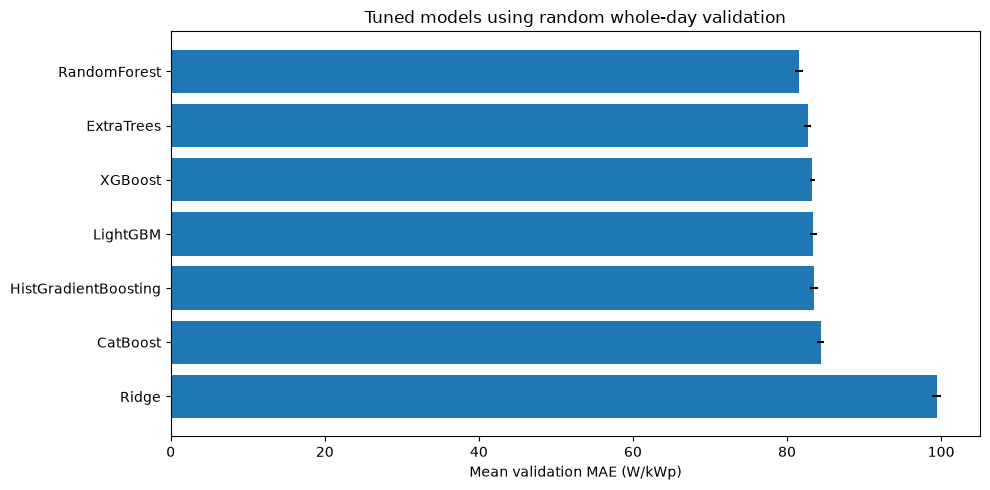

In [10]:
comparison = (
    pd.DataFrame(search_summaries)
    .sort_values("mean_CV_MAE")
    .reset_index(drop=True)
)

display(comparison)

BEST_MODEL_NAME = str(comparison.iloc[0]["model"])
BEST_PARAMETERS = best_parameters[BEST_MODEL_NAME]

print("Selected learned model:", BEST_MODEL_NAME)
print("Selected parameters:", BEST_PARAMETERS)

shared_comparison = comparison[[
    "model",
    "shared_rows_CV_MAE",
    "shared_rows_CV_RMSE",
]].copy()

baseline_summary = pd.DataFrame([{
    "model": "PreviousDayBaseline",
    "shared_rows_CV_MAE": (
        baseline_results["MAE_W_per_kWp"].mean()
    ),
    "shared_rows_CV_RMSE": (
        baseline_results["RMSE_W_per_kWp"].mean()
    ),
}])

shared_comparison = pd.concat(
    [shared_comparison, baseline_summary],
    ignore_index=True,
).sort_values("shared_rows_CV_MAE")

shared_comparison.to_csv(
    RESULT_FOLDER / "cv_shared_baseline_comparison.csv",
    index=False,
)

display(shared_comparison)

plot_data = comparison.sort_values("mean_CV_MAE")

plt.figure(figsize=(10, 5))

plt.barh(
    plot_data["model"],
    plot_data["mean_CV_MAE"],
    xerr=plot_data["std_CV_MAE"],
)

plt.xlabel("Mean validation MAE (W/kWp)")
plt.title("Tuned models using random whole-day validation")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    RESULT_FOLDER / "tuned_model_comparison.png",
    dpi=160,
)

plt.show()

10. Train the selected model and evaluate the final test data
Run this after finishing model selection. Avoid repeatedly changing models based on final-test results.
The selected model is fitted on all development rows and evaluated on the held-out dates.

In [11]:
best_model = clone(
    MODEL_SPECS[BEST_MODEL_NAME]["pipeline"]
).set_params(**BEST_PARAMETERS)

started = time.perf_counter()

with threadpool_limits(limits=MODEL_THREADS):
    best_model.fit(X_dev, y_dev)

final_fit_seconds = time.perf_counter() - started

with threadpool_limits(limits=MODEL_THREADS):
    test_predictions = postprocess_predictions(
        best_model.predict(X_test)
    )

test_actual = y_test.to_numpy(dtype=float)
test_ids = meta_test["inverterSn"].to_numpy()

test_metrics = calculate_metrics(
    test_actual,
    test_predictions,
    test_ids,
)

final_report = pd.DataFrame([{
    "model": BEST_MODEL_NAME,
    "fit_seconds": final_fit_seconds,
    **test_metrics,
}])

final_report.to_csv(
    RESULT_FOLDER / "final_test_metrics.csv",
    index=False,
)

display(final_report)

# Compare both methods on identical test rows.
baseline_available = np.isfinite(baseline_test)

shared_test_records = []

if baseline_available.any():
    for model_name, predictions in [
        (BEST_MODEL_NAME, test_predictions),
        ("PreviousDayBaseline", baseline_test),
    ]:
        shared_test_records.append({
            "model": model_name,
            **calculate_metrics(
                test_actual[baseline_available],
                predictions[baseline_available],
                test_ids[baseline_available],
            ),
        })

    shared_test_results = pd.DataFrame(shared_test_records)

    shared_test_results.to_csv(
        RESULT_FOLDER / "final_test_baseline_comparison.csv",
        index=False,
    )

    display(shared_test_results)

print(
    "Baseline availability on test rows:",
    f"{baseline_available.mean() * 100:.2f}%",
)

,model,fit_seconds,rows,MAE_W_per_kWp,RMSE_W_per_kWp,R2,macro_device_MAE
0,RandomForest,614.734577,149616,80.62465,119.969798,0.750102,79.057078


,model,rows,MAE_W_per_kWp,RMSE_W_per_kWp,R2,macro_device_MAE
0,RandomForest,142159,80.683423,119.696794,0.750434,78.196586
1,PreviousDayBaseline,142159,98.609979,157.941685,0.565476,93.419614


Baseline availability on test rows: 95.02%


11. Save predictions, per-device results, and the model
This block checks array lengths and saves metadata for the random-day split. It does not reference the old chronological variables such as test_start or VALIDATION_DAYS.
The block you supplied contains no traceback, so its original failure cannot be identified from the code alone.

In [12]:
RESULT_FOLDER.mkdir(parents=True, exist_ok=True)

test_output = meta_test.copy().reset_index(drop=True)

test_actual = np.asarray(
    test_actual,
    dtype=float,
).reshape(-1)

test_predictions = np.asarray(
    test_predictions,
    dtype=float,
).reshape(-1)

baseline_test = np.asarray(
    baseline_test,
    dtype=float,
).reshape(-1)

lengths = {
    "meta_test": len(test_output),
    "test_actual": len(test_actual),
    "test_predictions": len(test_predictions),
    "baseline_test": len(baseline_test),
}

if len(set(lengths.values())) != 1:
    raise ValueError(
        f"Test-array lengths do not match: {lengths}"
    )

if not np.isfinite(test_actual).all():
    raise ValueError("Nonfinite actual test values")

if not np.isfinite(test_predictions).all():
    raise ValueError("Nonfinite test predictions")

test_output["actual_W_per_kWp"] = test_actual
test_output["predicted_W_per_kWp"] = test_predictions
test_output["baseline_W_per_kWp"] = baseline_test

capacities = test_output[
    "pv_capacity_kwp"
].to_numpy(dtype=float)

test_output["actual_power_kw"] = (
    test_actual * capacities / 1000
)

test_output["predicted_power_kw"] = (
    test_predictions * capacities / 1000
)

test_output["baseline_power_kw"] = (
    baseline_test * capacities / 1000
)

test_output["absolute_error_W_per_kWp"] = np.abs(
    test_actual - test_predictions
)

training_devices = set(meta_dev["inverterSn"])

test_output["inverter_seen_in_training"] = (
    test_output["inverterSn"].isin(training_devices)
)

test_output.to_csv(
    RESULT_FOLDER / "final_test_predictions.csv",
    index=False,
)

device_results = []

for inverter_sn, group in test_output.groupby("inverterSn"):
    device_results.append({
        "inverterSn": str(inverter_sn),
        "seen_in_training": bool(
            group["inverter_seen_in_training"].iloc[0]
        ),
        **calculate_metrics(
            group["actual_W_per_kWp"],
            group["predicted_W_per_kWp"],
            group["inverterSn"],
        ),
    })

device_results = (
    pd.DataFrame(device_results)
    .sort_values("MAE_W_per_kWp", ascending=False)
    .reset_index(drop=True)
)

device_results.to_csv(
    RESULT_FOLDER / "final_test_metrics_by_inverter.csv",
    index=False,
)

display(device_results)

# Also report seen and unseen inverter groups separately.
seen_status_results = []

for seen, group in test_output.groupby(
    "inverter_seen_in_training"
):
    seen_status_results.append({
        "group": (
            "Seen in training"
            if seen
            else "Unseen in training"
        ),
        "inverters": int(group["inverterSn"].nunique()),
        **calculate_metrics(
            group["actual_W_per_kWp"],
            group["predicted_W_per_kWp"],
            group["inverterSn"],
        ),
    })

seen_status_results = pd.DataFrame(seen_status_results)

seen_status_results.to_csv(
    RESULT_FOLDER / "final_test_metrics_by_seen_status.csv",
    index=False,
)

display(seen_status_results)

MODEL_FILE = RESULT_FOLDER / "best_tuned_model.joblib"

joblib.dump(best_model, MODEL_FILE)

metadata = {
    "model_name": BEST_MODEL_NAME,
    "best_parameters": BEST_PARAMETERS,
    "features": FEATURE_COLUMNS,
    "target": TARGET_COLUMN,
    "target_unit": "W/kWp",
    "data_file": str(DATA_FILE),
    "split_method": (
        "Random whole local calendar days across all devices"
    ),
    "test_day_fraction_requested": TEST_FRACTION,
    "development_days": int(meta_dev["_date"].nunique()),
    "test_days": int(meta_test["_date"].nunique()),
    "development_rows": len(X_dev),
    "test_rows": len(X_test),
    "validation_method": "Repeated random whole-day splits",
    "validation_folds": N_FOLDS,
    "validation_day_fraction": CV_VALIDATION_FRACTION,
    "selection_metric": "Mean random whole-day validation MAE",
    "prediction_postprocessing": (
        "Clip negative predictions to zero"
    ),
    "baseline": (
        "Previous calendar day, same inverter and time slot"
    ),
    "baseline_forecast_issue_time": (
        "00:00 Asia/Colombo each target day"
    ),
    "baseline_observation_policy": (
        "Previous-day actual observations may come from any split. "
        "They are used only for baseline evaluation, "
        "not as model inputs."
    ),
    "weather_input": "Historical estimates",
    "evaluation_scope": (
        "Held-out historical dates. Training may contain "
        "dates later than test dates. This does not establish "
        "future forecasting performance."
    ),
    "excluded_devices": EXCLUDED_DEVICES,
    "seed": SEED,
    "cv_seed": SEED + 1,
}

with (RESULT_FOLDER / "training_metadata.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
        default=json_default,
    )

print("Saved model:", MODEL_FILE)
print("Results folder:", RESULT_FOLDER)

,inverterSn,seen_in_training,rows,MAE_W_per_kWp,RMSE_W_per_kWp,R2,macro_device_MAE
0,1801150249130001,True,4709,131.868008,177.615502,0.584685,131.868008
1,1031720256240537,True,662,118.079092,157.269911,0.577618,118.079092
2,1801150243110419,True,2420,104.882304,147.003168,0.614536,104.882304
3,1805060251150088,True,4245,101.531936,147.302378,0.709017,101.531936
4,1801160237150003,True,1087,100.334640,147.695258,0.728010,100.334640
5,180115023C230019,True,8378,95.319196,129.693888,0.745335,95.319196
6,1802060236200014,True,9986,92.380690,132.897101,0.707644,92.380690
7,1031721265270157,True,309,92.044619,123.902839,0.551877,92.044619
8,1805040241190014,True,8026,90.037381,130.690387,0.778505,90.037381
9,180115025B120119,True,348,89.917768,129.253569,0.719160,89.917768


,group,inverters,rows,MAE_W_per_kWp,RMSE_W_per_kWp,R2,macro_device_MAE
0,Seen in training,42,149616,80.62465,119.969798,0.750102,79.057078


Saved model: C:\Users\pkmpp\Documents\GitHub\J26-DS-323\experiments\pasan\after 11,20,23,30,36,43,46\gridsearch_random_days\best_tuned_model.joblib
Results folder: C:\Users\pkmpp\Documents\GitHub\J26-DS-323\experiments\pasan\after 11,20,23,30,36,43,46\gridsearch_random_days


## using saved model

In [13]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd


RESULT_FOLDER = Path(
    r"C:\Users\pkmpp\Documents\GitHub\J26-DS-323\experiments\pasan\after 11,20,23,30,36,43,46\gridsearch_random_days"
)

saved_model = joblib.load(
    RESULT_FOLDER / "best_tuned_model.joblib"
)

with (RESULT_FOLDER / "training_metadata.json").open(
    "r",
    encoding="utf-8",
) as file:
    model_metadata = json.load(file)

FEATURE_COLUMNS = model_metadata["features"]

print("Loaded model:", model_metadata["model_name"])
print("Required feature order:")

for number, name in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{number:2}. {name}")

Loaded model: RandomForest
Required feature order:
 1. weather_temperature_c
 2. weather_relative_humidity_pct
 3. weather_wind_speed_ms
 4. weather_cloud_cover_pct
 5. weather_cloud_cover_low_pct
 6. weather_cloud_cover_mid_pct
 7. weather_cloud_cover_high_pct
 8. weather_ghi_instant_wm2
 9. weather_dni_instant_wm2
10. weather_dhi_instant_wm2
11. weather_preceding_hour_precipitation_mm
12. weather_preceding_hour_rain_mm
13. sun_elevation_deg
14. sun_azimuth_sin
15. sun_azimuth_cos
16. latitude
17. longitude
18. pv_capacity_kwp
19. time_of_day_sin
20. time_of_day_cos
21. day_of_year_sin
22. day_of_year_cos


In [17]:
def predict_solar_power(feature_values):
    """
    Predict solar generation using the saved pipeline.

    Parameters
    ----------
    feature_values : list or list of lists
        One row of feature values, or multiple rows.
        Values must follow FEATURE_COLUMNS order.

    Returns
    -------
    pandas.DataFrame
        Predicted normalized power in W/kWp,
        installed capacity in kWp, and predicted power in kW.
    """
    values = np.asarray(feature_values, dtype=float)

    if values.ndim == 1:
        values = values.reshape(1, -1)

    if values.ndim != 2:
        raise ValueError(
            "Provide one list of features or a list of feature lists."
        )

    if values.shape[0] == 0:
        raise ValueError("Provide at least one input row.")

    if values.shape[1] != len(FEATURE_COLUMNS):
        raise ValueError(
            f"Each row must contain {len(FEATURE_COLUMNS)} values "
            f"in the training feature order; received "
            f"{values.shape[1]}."
        )

    if np.isinf(values).any():
        raise ValueError(
            "Inputs contain infinity. Use np.nan for missing features."
        )

    inputs = pd.DataFrame(
        values,
        columns=FEATURE_COLUMNS,
    )

    capacities = inputs["pv_capacity_kwp"].to_numpy()

    if (
        ~np.isfinite(capacities)
        | (capacities <= 0)
    ).any():
        raise ValueError(
            "pv_capacity_kwp must be a finite positive number."
        )

    predictions = np.asarray(
        saved_model.predict(inputs),
        dtype=float,
    ).reshape(-1)

    if not np.isfinite(predictions).all():
        raise ValueError("Model produced nonfinite predictions.")

    # Same postprocessing used during evaluation.
    predictions = np.maximum(predictions, 0)

    return pd.DataFrame({
        "predicted_W_per_kWp": predictions,
        "pv_capacity_kwp": capacities,
        "predicted_W": predictions * capacities,
        "predicted_power_kw": (
            predictions * capacities / 1000
        ),
    })

In [18]:
input_variables = [
    30.0,       # weather_temperature_c
    75.0,       # weather_relative_humidity_pct
    2.5,        # weather_wind_speed_ms
    35.0,       # weather_cloud_cover_pct
    20.0,       # weather_cloud_cover_low_pct
    15.0,       # weather_cloud_cover_mid_pct
    10.0,       # weather_cloud_cover_high_pct
    750.0,      # weather_ghi_instant_wm2
    600.0,      # weather_dni_instant_wm2
    180.0,      # weather_dhi_instant_wm2
    0.0,        # weather_preceding_hour_precipitation_mm
    0.0,        # weather_preceding_hour_rain_mm
    65.0,       # sun_elevation_deg
    0.5,        # sun_azimuth_sin
    -0.8660254, # sun_azimuth_cos
    6.0535,     # latitude
    80.2210,    # longitude
    5.0,        # pv_capacity_kwp
    0.0,        # time_of_day_sin: noon
    -1.0,       # time_of_day_cos: noon
    0.0,        # day_of_year_sin: January 1
    1.0,        # day_of_year_cos: January 1
]

prediction = predict_solar_power(input_variables)

display(prediction)

,predicted_W_per_kWp,pv_capacity_kwp,predicted_W,predicted_power_kw
0,446.504529,5.0,2232.522643,2.232523


In [19]:
input_variables = [
    28.6,       # weather_temperature_c
    78,       # weather_relative_humidity_pct
    0.8,        # weather_wind_speed_ms
    100,       # weather_cloud_cover_pct
    8,       # weather_cloud_cover_low_pct
    0,       # weather_cloud_cover_mid_pct
    99,       # weather_cloud_cover_high_pct
    415.8,      # weather_ghi_instant_wm2
    794.5,      # weather_dni_instant_wm2
    107.5,      # weather_dhi_instant_wm2
    0.0,        # weather_preceding_hour_precipitation_mm
    0.0,        # weather_preceding_hour_rain_mm
    30.164640333382568,       # sun_elevation_deg
    103.70136712814208,        # sun_azimuth_sin
    -0.2368613280223277, # sun_azimuth_cos
    6.2353,     # latitude
    80.055,    # longitude
    15.0,        # pv_capacity_kwp
    0.7933533402912352,        # time_of_day_sin: noon
    -0.6087614290087207,       # time_of_day_cos: noon
    0.8296770135526188,        # day_of_year_sin: January 1
    0.5582437220268648,        # day_of_year_cos: January 1
]

prediction = predict_solar_power(input_variables)

display(prediction)

,predicted_W_per_kWp,pv_capacity_kwp,predicted_W,predicted_power_kw
0,331.814352,15.0,4977.215274,4.977215


In [ ]:
# # Replace these with the feature lists for your actual time slots.
# multiple_inputs = [
#     input_variables,
#     input_variables,
# ]

# predictions = predict_solar_power(multiple_inputs)

# display(predictions)